# ResNet — Deep Residual Learning for Image Recognition

**Paper:** He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep Residual Learning for Image Recognition. *CVPR 2016*. https://arxiv.org/abs/1512.03385

**Implementation:** `hale_core/nn/vision/cnn/resnet.py`

> ResNet introduces shortcut (skip) connections that allow gradients to flow directly through many layers, solving the degradation problem and enabling training of networks with 100–1000+ layers.

> 📄 **Paper:** He, Zhang, Ren & Sun (2016). Deep Residual Learning for Image Recognition. CVPR 2016.
> 🔗 **Link:** <https://arxiv.org/abs/1512.03385>
> 🧩 **Implementation:** `hale_core/nn/vision/cnn/resnet.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> STEM["stem: conv 7×7 /2 · BN · ReLU · maxpool /2<br/>(B, 64, 56, 56)"]:::stage
  STEM --> L1["layer1 ×n (stride 1) → C2 /4"]:::stage --> L2["layer2 ×n (stride 2) → C3 /8"]:::stage
  L2 --> L3["layer3 ×n (stride 2) → C4 /16"]:::stage --> L4["layer4 ×n (stride 2) → C5 /32"]:::stage
  L4 --> GAP["global avg pool"]:::block --> OUT
  subgraph BLK["Bottleneck (ResNet-50+)"]
    direction LR
    X["x"] --> A["1×1 reduce · BN · ReLU"]:::block --> B["3×3 (stride s) · BN · ReLU"]:::block --> C["1×1 expand ×4 · BN"]:::block
    C --> ADD(("+")) --> R["ReLU"]:::block
    X -->|"identity or 1×1 /s projection"| ADD
  end
  L1 -.-> BLK
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture Overview

```
Input [B, 3, 224, 224]
       │
  ┌────▼────────────────────────────┐
  │  STEM                           │
  │  7×7 conv, stride=2 → BN→ReLU  │  → [B,  64, 112, 112]
  │  MaxPool, stride=2              │  → [B,  64,  56,  56]
  └─────────────────────────────────┘
       │
  ┌────▼──────────────────────────────────────┐
  │  STAGE 0  (stride=1, channels=64/256)     │
  │  [BasicBlock×2] or [Bottleneck×3]         │  → [B,  64/256,  56, 56]
  └───────────────────────────────────────────┘
       │
  ┌────▼──────────────────────────────────────┐
  │  STAGE 1  (stride=2, channels=128/512)    │
  │  [BasicBlock×2/4] or [Bottleneck×4]       │  → [B, 128/512,  28, 28]
  └───────────────────────────────────────────┘
       │
  ┌────▼──────────────────────────────────────┐
  │  STAGE 2  (stride=2, channels=256/1024)   │
  │  [BasicBlock×2/6] or [Bottleneck×6/23]    │  → [B, 256/1024, 14, 14]
  └───────────────────────────────────────────┘
       │
  ┌────▼──────────────────────────────────────┐
  │  STAGE 3  (stride=2, channels=512/2048)   │
  │  [BasicBlock×2/3] or [Bottleneck×3/8]     │  → [B, 512/2048,  7,  7]
  └───────────────────────────────────────────┘
       │
  ┌────▼──────────────────────────────────┐
  │  GlobalAvgPool → Flatten → Dropout   │  → [B, embed_dim]
  └───────────────────────────────────────┘

BasicBlock (ResNet-18/34):    Bottleneck (ResNet-50/101/152/200):
  x → 3×3 conv → BN → ReLU     x → 1×1 conv → BN → ReLU
    → 3×3 conv → BN               → 3×3 conv → BN → ReLU
    → (+x via skip)               → 1×1 conv → BN
    → ReLU                        → (+x via skip)
                                  → ReLU
```

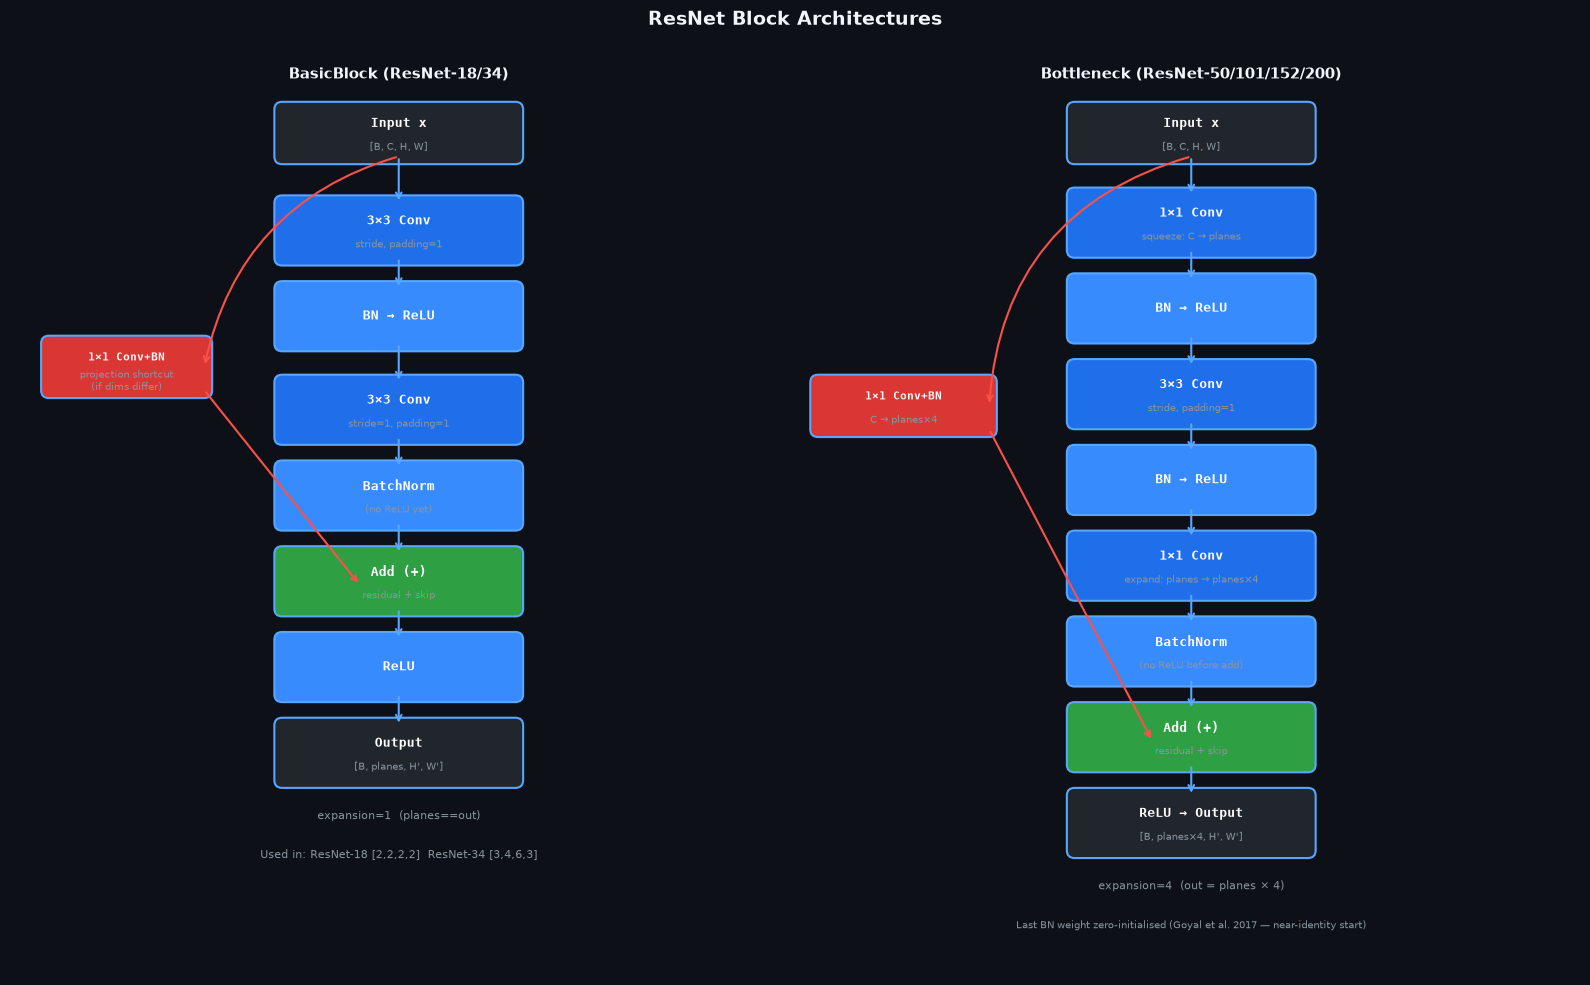

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(16, 10))
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('#0d1117')
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 12)
    ax.axis('off')

# ── Helper ────────────────────────────────────────────────────────────────────
def box(ax, x, y, w, h, label, sublabel='', color='#1f6feb', text_color='white', fontsize=9):
    rect = FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.1',
                           facecolor=color, edgecolor='#58a6ff', linewidth=1.5)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2 + (0.12 if sublabel else 0), label,
            ha='center', va='center', color=text_color,
            fontsize=fontsize, fontweight='bold', fontfamily='monospace')
    if sublabel:
        ax.text(x + w/2, y + h/2 - 0.18, sublabel,
                ha='center', va='center', color='#8b949e', fontsize=7)

def arrow(ax, x1, y1, x2, y2, color='#58a6ff'):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=color, lw=1.5))

# ══════════════════════════════════════════════════════════
# LEFT: BasicBlock (ResNet-18/34)
# ══════════════════════════════════════════════════════════
ax = axes[0]
ax.text(5, 11.5, 'BasicBlock (ResNet-18/34)', ha='center', color='#f0f6fc',
        fontsize=11, fontweight='bold')

# input
box(ax, 3.5, 10.5, 3, 0.6, 'Input x', '[B, C, H, W]', color='#21262d')
# 3x3 conv
box(ax, 3.5, 9.2, 3, 0.7, '3×3 Conv', 'stride, padding=1', color='#1f6feb')
arrow(ax, 5, 10.5, 5, 9.9)
# BN+ReLU
box(ax, 3.5, 8.1, 3, 0.7, 'BN → ReLU', '', color='#388bfd')
arrow(ax, 5, 9.2, 5, 8.8)
# 3x3 conv 2
box(ax, 3.5, 6.9, 3, 0.7, '3×3 Conv', 'stride=1, padding=1', color='#1f6feb')
arrow(ax, 5, 8.1, 5, 7.6)
# BN (no relu yet)
box(ax, 3.5, 5.8, 3, 0.7, 'BatchNorm', '(no ReLU yet)', color='#388bfd')
arrow(ax, 5, 6.9, 5, 6.5)
# skip connection
box(ax, 0.5, 7.5, 2, 0.6, '1×1 Conv+BN', 'projection shortcut\n(if dims differ)', color='#da3633', fontsize=8)
ax.annotate('', xy=(2.5, 7.8), xytext=(5, 10.5),
            arrowprops=dict(arrowstyle='->', color='#f85149', lw=1.5,
                            connectionstyle='arc3,rad=0.3'))
# add
box(ax, 3.5, 4.7, 3, 0.7, 'Add (+)', 'residual + skip', color='#2ea043')
arrow(ax, 5, 5.8, 5, 5.4)
ax.annotate('', xy=(4.5, 5.0), xytext=(2.5, 7.5),
            arrowprops=dict(arrowstyle='->', color='#f85149', lw=1.5))
# ReLU
box(ax, 3.5, 3.6, 3, 0.7, 'ReLU', '', color='#388bfd')
arrow(ax, 5, 4.7, 5, 4.3)
# output
box(ax, 3.5, 2.5, 3, 0.7, 'Output', '[B, planes, H\', W\']', color='#21262d')
arrow(ax, 5, 3.6, 5, 3.2)

ax.text(5, 2.0, 'expansion=1  (planes==out)', ha='center', color='#8b949e', fontsize=8)
ax.text(5, 1.5, 'Used in: ResNet-18 [2,2,2,2]  ResNet-34 [3,4,6,3]', ha='center', color='#8b949e', fontsize=8)

# ══════════════════════════════════════════════════════════
# RIGHT: Bottleneck (ResNet-50/101/152/200)
# ══════════════════════════════════════════════════════════
ax = axes[1]
ax.text(5, 11.5, 'Bottleneck (ResNet-50/101/152/200)', ha='center',
        color='#f0f6fc', fontsize=11, fontweight='bold')

box(ax, 3.5, 10.5, 3, 0.6, 'Input x', '[B, C, H, W]', color='#21262d')
# 1x1 squeeze
box(ax, 3.5, 9.3, 3, 0.7, '1×1 Conv', 'squeeze: C → planes', color='#1f6feb')
arrow(ax, 5, 10.5, 5, 10.0)
box(ax, 3.5, 8.2, 3, 0.7, 'BN → ReLU', '', color='#388bfd')
arrow(ax, 5, 9.3, 5, 8.9)
# 3x3
box(ax, 3.5, 7.1, 3, 0.7, '3×3 Conv', 'stride, padding=1', color='#1f6feb')
arrow(ax, 5, 8.2, 5, 7.8)
box(ax, 3.5, 6.0, 3, 0.7, 'BN → ReLU', '', color='#388bfd')
arrow(ax, 5, 7.1, 5, 6.7)
# 1x1 expand
box(ax, 3.5, 4.9, 3, 0.7, '1×1 Conv', 'expand: planes → planes×4', color='#1f6feb')
arrow(ax, 5, 6.0, 5, 5.6)
box(ax, 3.5, 3.8, 3, 0.7, 'BatchNorm', '(no ReLU before add)', color='#388bfd')
arrow(ax, 5, 4.9, 5, 4.5)
# skip
box(ax, 0.2, 7.0, 2.2, 0.6, '1×1 Conv+BN', 'C → planes×4', color='#da3633', fontsize=8)
ax.annotate('', xy=(2.4, 7.3), xytext=(5, 10.5),
            arrowprops=dict(arrowstyle='->', color='#f85149', lw=1.5,
                            connectionstyle='arc3,rad=0.35'))
# add
box(ax, 3.5, 2.7, 3, 0.7, 'Add (+)', 'residual + skip', color='#2ea043')
arrow(ax, 5, 3.8, 5, 3.4)
ax.annotate('', xy=(4.5, 3.0), xytext=(2.4, 7.0),
            arrowprops=dict(arrowstyle='->', color='#f85149', lw=1.5))
# relu
box(ax, 3.5, 1.6, 3, 0.7, 'ReLU → Output', '[B, planes×4, H\', W\']', color='#21262d')
arrow(ax, 5, 2.7, 5, 2.3)

ax.text(5, 1.1, 'expansion=4  (out = planes × 4)', ha='center', color='#8b949e', fontsize=8)
ax.text(5, 0.6, 'Last BN weight zero-initialised (Goyal et al. 2017 — near-identity start)', ha='center', color='#8b949e', fontsize=7)

plt.suptitle('ResNet Block Architectures', fontsize=14, color='#f0f6fc',
             fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

## 3. Key ideas

## Key Innovations

### 1. The Degradation Problem
Before ResNet, adding more layers to a network *hurt* accuracy on both training and test sets — not from overfitting, but because optimisation itself became harder. If an identity mapping were optimal, a plain network had no way to express it easily. ResNet solves this by reformulating the target:

Instead of learning the direct mapping H(x), each block learns the **residual** F(x) = H(x) − x.  
Then output = **F(x) + x** (the skip connection adds back x).

If the identity is optimal, F(x) → 0 is easy to learn. This makes optimisation far more tractable.

### 2. Two Block Designs
- **BasicBlock** (ResNet-18/34): Two 3×3 convolutions. Simple, fewer parameters, good for smaller models.
- **Bottleneck** (ResNet-50+): 1×1 squeeze → 3×3 conv → 1×1 expand (expansion=4). Reduces FLOPs since the 3×3 conv operates on *planes* channels, not *planes×4*. This allows deeper networks at similar cost.

### 3. Projection Shortcut
When input and output dimensions differ (either channel count or spatial size), the skip connection uses a 1×1 conv + BN. He et al. found this performs marginally better than zero-padding approaches.

### 4. Zero-Init of Last BN (Goyal et al. 2017)
The last BN in each residual branch is weight-initialized to 0. This makes each block an **identity at the start of training**, which stabilises gradients when training with large batches and improves convergence speed.

### 5. Stage Structure
| Stage | Stride | BasicBlock dim | Bottleneck dim | Output size (224px input) |
|-------|--------|----------------|----------------|---------------------------|
| Stem  | 4×     | 64             | 64             | 56 × 56                   |
| 0     | 1×     | 64             | 256            | 56 × 56                   |
| 1     | 2×     | 128            | 512            | 28 × 28                   |
| 2     | 2×     | 256            | 1024           | 14 × 14                   |
| 3     | 2×     | 512            | 2048           | 7 × 7                     |

### 6. Weight Initialisation
All convolutions use **Kaiming normal** (He init) with `fan_out` and `nonlinearity='relu'`. This correctly calibrates the variance of activations under ReLU, preventing vanishing/exploding gradients at initialisation.

## Component Walkthrough

### `BasicBlock` (lines 64–107 in `resnet.py`)
```python
class BasicBlock(nn.Module):
    expansion: int = 1  # output channels = planes * expansion = planes

    def __init__(self, in_planes, planes, stride=1, downsample=None):
        # First 3×3 conv — stride here performs spatial downsampling if stride>1
        self.conv1 = nn.Conv2d(in_planes, planes, 3, stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(planes)
        # Second 3×3 conv — always stride=1
        self.conv2 = nn.Conv2d(planes, planes, 3, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(planes)
        self.downsample = downsample  # None = identity shortcut

    def forward(self, x):
        identity = x
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))
        if self.downsample is not None:
            identity = self.downsample(x)  # project to match dims
        return F.relu(out + identity, inplace=True)  # RESIDUAL ADD
```

### `Bottleneck` (lines 110–160 in `resnet.py`)
```python
class Bottleneck(nn.Module):
    expansion: int = 4  # output = planes × 4

    def __init__(self, in_planes, planes, stride=1, downsample=None):
        self.conv1 = nn.Conv2d(in_planes, planes, 1, bias=False)           # 1×1 squeeze
        self.conv2 = nn.Conv2d(planes, planes, 3, stride=stride,           # 3×3 main
                                padding=1, bias=False)
        self.conv3 = nn.Conv2d(planes, planes * 4, 1, bias=False)          # 1×1 expand
        # No ReLU on self.bn3 output — applied AFTER residual add

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)                # squeeze
        out = F.relu(self.bn2(self.conv2(out)), inplace=True)              # 3×3
        out = self.bn3(self.conv3(out))                                    # expand (no act)
        return F.relu(out + (self.downsample(x) if self.downsample else x))
```

### `ResNet._make_stage` (lines 241–271 in `resnet.py`)
```python
def _make_stage(self, block, planes, n_blocks, stride):
    downsample = None
    out_channels = planes * block.expansion
    # Projection shortcut needed if spatial resolution OR channel count changes
    if stride != 1 or self._in_planes != out_channels:
        downsample = nn.Sequential(
            nn.Conv2d(self._in_planes, out_channels, 1, stride=stride, bias=False),
            nn.BatchNorm2d(out_channels),
        )
    blocks = [block(self._in_planes, planes, stride, downsample)]
    self._in_planes = out_channels
    # Subsequent blocks: same channels, stride=1, no downsample
    for _ in range(1, n_blocks):
        blocks.append(block(self._in_planes, planes))
    return nn.Sequential(*blocks)
```

**Why no bias in conv layers?**  
BatchNorm subtracts the mean and adds a learnable bias (β). A bias in the conv layer before BN would be cancelled out by BN's mean subtraction — so it's redundant and wastes parameters.

**Why Kaiming init?**  
A standard normal init would produce activations whose variance grows or shrinks exponentially with depth through ReLU. Kaiming normal (He init) ensures `Var(output) = Var(input)` through a ReLU layer, maintaining stable gradient magnitudes from input to output.

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/cnn/resnet.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>cnn/resnet.py</code></summary>

```text
ResNet Vision Backbones
=======================

Implements the full ResNet family (He et al. 2016, "Deep Residual Learning for Image
Recognition", https://arxiv.org/abs/1512.03385).

Architecture
------------
ResNet is built from stacked residual blocks of two designs:

  BasicBlock (used in ResNet-18 and ResNet-34):
    3×3 conv → BN → ReLU → 3×3 conv → BN → (+residual) → ReLU
    Expansion factor = 1 (output channels == input channels).

  Bottleneck (used in ResNet-50/101/152/200):
    1×1 conv (reduce) → BN → ReLU
    3×3 conv          → BN → ReLU
    1×1 conv (expand) → BN → (+residual) → ReLU
    Expansion factor = 4 (output channels = planes × 4).

Stage structure:
  Stem    : 7×7 conv, stride 2 → BN → ReLU → MaxPool stride 2  → 1/4 resolution
  Stage 0 : 64  channels, stride 1                               → 1/4 resolution
  Stage 1 : 128 channels, stride 2                               → 1/8 resolution
  Stage 2 : 256 channels, stride 2                               → 1/16 resolution
  Stage 3 : 512 channels, stride 2                               → 1/32 resolution

Weight initialisation:
  Convolutions: Kaiming normal (He init) for correct variance under ReLU.
  BatchNorm:    weight=1, bias=0 (standard identity init).
  Zero-init of the last BN in each residual branch (Goyal et al. "Accurate, Large
  Minibatch SGD"), which improves convergence stability at large batch sizes.

Registered names
----------------
  resnet18   — BasicBlock × [2, 2, 2, 2],  embed_dim=512
  resnet34   — BasicBlock × [3, 4, 6, 3],  embed_dim=512
  resnet50   — Bottleneck × [3, 4, 6, 3],  embed_dim=2048
  resnet101  — Bottleneck × [3, 4, 23, 3], embed_dim=2048
  resnet152  — Bottleneck × [3, 8, 36, 3], embed_dim=2048
  resnet200  — Bottleneck × [3, 24, 36, 3],embed_dim=2048

Citation
--------
  He et al. (2016). Deep Residual Learning for Image Recognition. CVPR.
  Goyal et al. (2017). Accurate, Large Minibatch SGD. arXiv:1706.02677.
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### 4.2 `cnn/resnet.py`, definition by definition

**`BasicBlock`** - Residual block for ResNet-18/34.

In [5]:
class BasicBlock(nn.Module):
    """Residual block for ResNet-18/34.

    Uses two 3×3 convolutions without channel bottlenecking (expansion=1).
    This design is cheaper per block but stacks more layers to reach target capacity.

    Args:
        in_planes:  Number of input channels.
        planes:     Number of output channels (== in_planes × expansion = in_planes).
        stride:     Stride for the first conv; when >1, spatial downsampling occurs.
        downsample: Optional projection shortcut when input/output shapes differ.
    """

    expansion: int = 1  # output channels = planes * expansion

    def __init__(
        self,
        in_planes: int,
        planes: int,
        stride: int = 1,
        downsample: Optional[nn.Module] = None,
    ) -> None:
        super().__init__()
        # First 3×3 conv; stride here performs spatial downsampling if stride>1
        self.conv1 = nn.Conv2d(in_planes, planes, 3, stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(planes)
        # Second 3×3 conv; always stride=1 to preserve resolution after first conv
        self.conv2 = nn.Conv2d(planes, planes, 3, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(planes)
        # Shortcut: may be None (identity) or a 1×1 projection to match dims
        self.downsample = downsample

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        identity = x

        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))

        # Add shortcut BEFORE final activation — core residual learning formula
        if self.downsample is not None:
            identity = self.downsample(x)

        out = F.relu(out + identity, inplace=True)
        return out

**`Bottleneck`** - Residual bottleneck block for ResNet-50/101/152/200.

In [6]:
class Bottleneck(nn.Module):
    """Residual bottleneck block for ResNet-50/101/152/200.

    Uses a 1×1 → 3×3 → 1×1 pattern (expansion=4), significantly reducing FLOPs
    compared to two stacked 3×3 convolutions when channel counts are large.

    Args:
        in_planes:  Number of input channels.
        planes:     "bottleneck width"; output channels = planes × expansion = planes × 4.
        stride:     Stride for the 3×3 conv; when >1, spatial downsampling occurs.
        downsample: Optional projection shortcut when input/output shapes differ.
    """

    expansion: int = 4  # output channels = planes * 4

    def __init__(
        self,
        in_planes: int,
        planes: int,
        stride: int = 1,
        downsample: Optional[nn.Module] = None,
    ) -> None:
        super().__init__()
        out_channels = planes * self.expansion

        # 1×1 conv: reduce channels from in_planes to planes (the "bottleneck")
        self.conv1 = nn.Conv2d(in_planes, planes, 1, bias=False)
        self.bn1   = nn.BatchNorm2d(planes)

        # 3×3 conv: main spatial processing; stride here for downsampling
        self.conv2 = nn.Conv2d(planes, planes, 3, stride=stride, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(planes)

        # 1×1 conv: expand channels back to planes × 4
        self.conv3 = nn.Conv2d(planes, out_channels, 1, bias=False)
        self.bn3   = nn.BatchNorm2d(out_channels)

        self.downsample = downsample

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        identity = x

        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = F.relu(self.bn2(self.conv2(out)), inplace=True)
        out = self.bn3(self.conv3(out))  # no activation before add

        if self.downsample is not None:
            identity = self.downsample(x)

        out = F.relu(out + identity, inplace=True)
        return out

**`ResNet`** - Generic ResNet backbone.

In [7]:
class ResNet(BaseVisionBackbone):
    """Generic ResNet backbone.

    Implements the full multi-stage ResNet as a dense feature extractor, returning
    4-scale feature maps for use with FPN/BEV heads and a global pooled embedding
    for VLM/action encoders.

    Args:
        block:      Block class — BasicBlock or Bottleneck.
        layers:     Number of blocks in each of the 4 stages.
        img_size:   Expected input spatial resolution (assumed square).
        in_chans:   Input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied after global pooling.
        out_indices: Which stages to include in feature_maps (default: all 4).
    """

    def __init__(
        self,
        block: Type[Union[BasicBlock, Bottleneck]],
        layers: list[int],
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans, drop_rate=drop_rate, out_indices=out_indices)

        self._block = block
        self._layers = layers

        # embed_dim is the channel count of stage 3 output
        self.embed_dim  = 512 * block.expansion
        # feature_dims matches channels at each of the 4 stages
        self.feature_dims = [
            64  * block.expansion if block.expansion > 1 else 64,
            128 * block.expansion if block.expansion > 1 else 128,
            256 * block.expansion if block.expansion > 1 else 256,
            512 * block.expansion if block.expansion > 1 else 512,
        ]
        # For BasicBlock (expansion=1), channels are [64, 128, 256, 512]
        # For Bottleneck (expansion=4), channels are [256, 512, 1024, 2048]
        self.feature_dims = [
            64,
            128,
            256,
            512,
        ] if block.expansion == 1 else [256, 512, 1024, 2048]

        self._in_planes = 64  # current channel count, updated as stages are built

        # ── Stem: 7×7 conv + BN + ReLU + MaxPool ─────────────────────────────
        # Downsamples input from H × W to H/4 × W/4 before stage 0.
        self.stem = nn.Sequential(
            nn.Conv2d(in_chans, 64, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )

        # ── 4 residual stages ─────────────────────────────────────────────────
        # Stage 0: stride=1 (no downsampling, maintains H/4)
        self.stage0 = self._make_stage(block,  64, layers[0], stride=1)
        # Stages 1–3: stride=2 each, progressively halving resolution
        self.stage1 = self._make_stage(block, 128, layers[1], stride=2)
        self.stage2 = self._make_stage(block, 256, layers[2], stride=2)
        self.stage3 = self._make_stage(block, 512, layers[3], stride=2)

        # ── Global average pool + optional dropout ────────────────────────────
        self.pool    = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(drop_rate) if drop_rate > 0.0 else nn.Identity()

        # Ordered list of stage modules for freeze_up_to_stage convenience
        self._stages = [self.stage0, self.stage1, self.stage2, self.stage3]

        self._init_weights()

    def _make_stage(
        self,
        block: Type[Union[BasicBlock, Bottleneck]],
        planes: int,
        n_blocks: int,
        stride: int,
    ) -> nn.Sequential:
        """Build one ResNet stage as an nn.Sequential of `n_blocks` residual blocks.

        The first block handles any spatial downsampling (stride argument) and
        any channel dimension change (via a 1×1 projection shortcut).  Subsequent
        blocks always have stride=1 and no shortcut needed.
        """
        downsample = None
        out_channels = planes * block.expansion

        # Need a projection shortcut if spatial resolution or channel count changes
        if stride != 1 or self._in_planes != out_channels:
            downsample = nn.Sequential(
                nn.Conv2d(self._in_planes, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

        blocks = [block(self._in_planes, planes, stride, downsample)]
        self._in_planes = out_channels

        # Subsequent blocks: in_planes == out_channels, stride=1, no downsample
        for _ in range(1, n_blocks):
            blocks.append(block(self._in_planes, planes))

        return nn.Sequential(*blocks)

    def _init_weights(self) -> None:
        """Kaiming normal for all conv layers; constant BN; zero last BN in blocks."""
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                # Kaiming normal: calibrates variance for ReLU nonlinearity
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

        # Zero-init the last BN in each residual branch so residual blocks start
        # as near-identity mappings — improves gradient flow at training start
        for m in self.modules():
            if isinstance(m, Bottleneck) and m.bn3 is not None:
                nn.init.zeros_(m.bn3.weight)
            elif isinstance(m, BasicBlock) and m.bn2 is not None:
                nn.init.zeros_(m.bn2.weight)

    # ── Forward pass ──────────────────────────────────────────────────────────

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run ResNet forward pass and return multi-scale features + pooled embedding.

        Args:
            x: Float32 tensor [B, in_chans, H, W].

        Returns:
            BackboneOutput:
              pooled_output — [B, embed_dim] global representation
              patch_tokens  — None (CNNs produce spatial maps, not tokens)
              feature_maps  — [stage0_out, stage1_out, stage2_out, stage3_out]
                              shapes: [B,64,H/4,W/4], [B,128,H/8,W/8],
                                      [B,256,H/16,W/16], [B,512,H/32,W/32]
                              (channels × 4 for Bottleneck models)
        """
        x = self.stem(x)           # [B, 64, H/4, W/4]

        s0 = self.stage0(x)        # [B, 64  or 256, H/4, W/4]
        s1 = self.stage1(s0)       # [B, 128 or 512, H/8, W/8]
        s2 = self.stage2(s1)       # [B, 256 or 1024, H/16, W/16]
        s3 = self.stage3(s2)       # [B, 512 or 2048, H/32, W/32]

        # Global pooled embedding: flatten spatial dims after AdaptiveAvgPool
        pooled = self.dropout(self.pool(s3).flatten(1))  # [B, embed_dim]

        # Select which scales to return
        all_maps = [s0, s1, s2, s3]
        if self.out_indices is not None:
            all_maps = [all_maps[i] for i in self.out_indices]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,    # CNNs have no patch token abstraction
            feature_maps=all_maps,
            attentions=None,
        )

    # ── Stage freezing ────────────────────────────────────────────────────────

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze the stem and stages 0 through `stage` (inclusive).

        Useful for fine-tuning: keep early low-level features fixed and only
        update later stages.

        Args:
            stage: 0-based stage index.  E.g. stage=1 freezes stem+stage0+stage1.

        Raises:
            ValueError: if stage is out of range [0, 3].
        """
        if stage < 0 or stage > 3:
            raise ValueError(f"stage must be in [0, 3], got {stage}")

        # Always freeze stem along with stage 0
        for p in self.stem.parameters():
            p.requires_grad_(False)

        for i in range(stage + 1):
            for p in self._stages[i].parameters():
                p.requires_grad_(False)

**`ResNet18`** - ResNet-18: BasicBlock × [2,2,2,2] — lightweight, fast, embed_dim=512.

In [8]:
@register_vision_backbone("resnet18")
class ResNet18(ResNet):
    """ResNet-18: BasicBlock × [2,2,2,2] — lightweight, fast, embed_dim=512."""
    arch_name  = "resnet18"
    embed_dim  = 512
    feature_dims = [64, 128, 256, 512]

    def __init__(self, **kwargs) -> None:
        super().__init__(BasicBlock, [2, 2, 2, 2], **kwargs)

**`ResNet34`** - ResNet-34: BasicBlock × [3,4,6,3] — better accuracy than 18, same embed_dim.

In [9]:
@register_vision_backbone("resnet34")
class ResNet34(ResNet):
    """ResNet-34: BasicBlock × [3,4,6,3] — better accuracy than 18, same embed_dim."""
    arch_name  = "resnet34"
    embed_dim  = 512
    feature_dims = [64, 128, 256, 512]

    def __init__(self, **kwargs) -> None:
        super().__init__(BasicBlock, [3, 4, 6, 3], **kwargs)

**`ResNet50`** - ResNet-50: Bottleneck × [3,4,6,3] — standard production backbone, embed_dim=2048.

In [10]:
@register_vision_backbone("resnet50")
class ResNet50(ResNet):
    """ResNet-50: Bottleneck × [3,4,6,3] — standard production backbone, embed_dim=2048."""
    arch_name  = "resnet50"
    embed_dim  = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(self, **kwargs) -> None:
        super().__init__(Bottleneck, [3, 4, 6, 3], **kwargs)

**`ResNet101`** - ResNet-101: Bottleneck × [3,4,23,3] — stronger features, 23 blocks in stage2.

In [11]:
@register_vision_backbone("resnet101")
class ResNet101(ResNet):
    """ResNet-101: Bottleneck × [3,4,23,3] — stronger features, 23 blocks in stage2."""
    arch_name  = "resnet101"
    embed_dim  = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(self, **kwargs) -> None:
        super().__init__(Bottleneck, [3, 4, 23, 3], **kwargs)

**`ResNet152`** - ResNet-152: Bottleneck × [3,8,36,3] — deep backbone for high-accuracy tasks.

In [12]:
@register_vision_backbone("resnet152")
class ResNet152(ResNet):
    """ResNet-152: Bottleneck × [3,8,36,3] — deep backbone for high-accuracy tasks."""
    arch_name  = "resnet152"
    embed_dim  = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(self, **kwargs) -> None:
        super().__init__(Bottleneck, [3, 8, 36, 3], **kwargs)

**`ResNet200`** - ResNet-200: Bottleneck × [3,24,36,3] — very deep, used in scaling studies.

In [13]:
@register_vision_backbone("resnet200")
class ResNet200(ResNet):
    """ResNet-200: Bottleneck × [3,24,36,3] — very deep, used in scaling studies."""
    arch_name  = "resnet200"
    embed_dim  = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(self, **kwargs) -> None:
        super().__init__(Bottleneck, [3, 24, 36, 3], **kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [14]:
DEMOS = {"resnet18": 11.7, "resnet50": 25.6}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['resnet101', 'resnet152', 'resnet18', 'resnet200', 'resnet34', 'resnet50']

resnet18  (ResNet18)
  pooled_output : (2, 512)   embed_dim = 512
  feature_map 0: (2, 64, 56, 56)   stride 4
  feature_map 1: (2, 128, 28, 28)   stride 8
  feature_map 2: (2, 256, 14, 14)   stride 16
  feature_map 3: (2, 512, 7, 7)   stride 32



resnet50  (ResNet50)
  pooled_output : (2, 2048)   embed_dim = 2048
  feature_map 0: (2, 256, 56, 56)   stride 4
  feature_map 1: (2, 512, 28, 28)   stride 8
  feature_map 2: (2, 1024, 14, 14)   stride 16
  feature_map 3: (2, 2048, 7, 7)   stride 32


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

In [15]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
resnet18                 11.18M     11.69M    11.7M    1.00  ✅
resnet50                 23.51M     25.56M    25.6M    1.00  ✅


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [16]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

resnet18: loss 4.1986 | 60/60 parameter tensors receive a finite gradient
resnet50: loss 2.1589 | 159/159 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [17]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

resnet18: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


resnet50: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

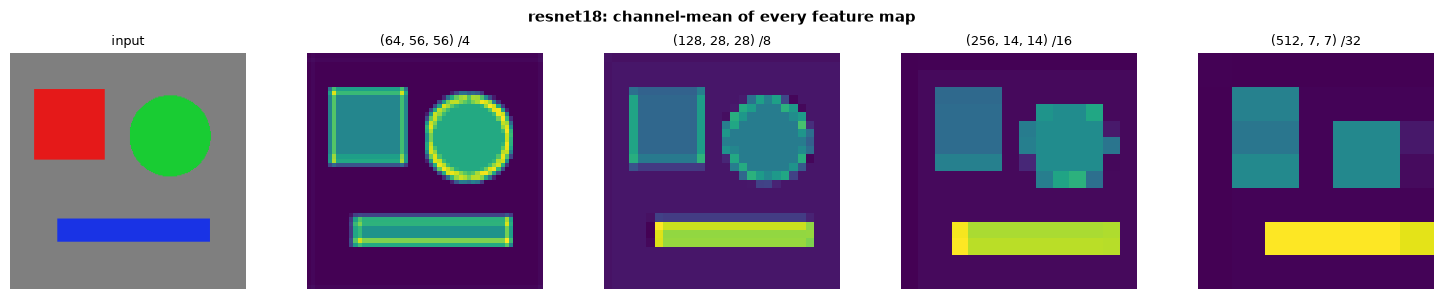

In [18]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [19]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [20]:
import sys

import torch

x = torch.randn(2, 3, 224, 224)

for name in ['resnet18', 'resnet50', 'resnet101']:
    bb = build_vision_backbone(name, img_size=224)
    bb.eval()
    with torch.no_grad():
        out = bb(x)
    print(f'{name:12s}  pooled={tuple(out.pooled_output.shape)}')
    print(f'  feature_maps: {[tuple(f.shape) for f in out.feature_maps]}')
    print(f'  parameters: {bb.num_parameters():,}')
    print()

# Freeze example
bb50 = build_vision_backbone('resnet50', img_size=224)
bb50.freeze_up_to_stage(1)  # freeze stem + stage0 + stage1
frozen = sum(1 for p in bb50.parameters() if not p.requires_grad)
trainable = sum(1 for p in bb50.parameters() if p.requires_grad)
print(f'After freeze_up_to_stage(1): {frozen} frozen, {trainable} trainable param groups')

resnet18      pooled=(2, 512)
  feature_maps: [(2, 64, 56, 56), (2, 128, 28, 28), (2, 256, 14, 14), (2, 512, 7, 7)]
  parameters: 11,176,512



resnet50      pooled=(2, 2048)
  feature_maps: [(2, 256, 56, 56), (2, 512, 28, 28), (2, 1024, 14, 14), (2, 2048, 7, 7)]
  parameters: 23,508,032



resnet101     pooled=(2, 2048)
  feature_maps: [(2, 256, 56, 56), (2, 512, 28, 28), (2, 1024, 14, 14), (2, 2048, 7, 7)]
  parameters: 42,500,160

After freeze_up_to_stage(1): 72 frozen, 87 trainable param groups


## Model Variants

| Model      | Block       | Layers         | embed_dim | Params  |
|------------|-------------|----------------|-----------|----------|
| resnet18   | BasicBlock  | [2, 2, 2, 2]   | 512       | ~11M    |
| resnet34   | BasicBlock  | [3, 4, 6, 3]   | 512       | ~21M    |
| resnet50   | Bottleneck  | [3, 4, 6, 3]   | 2048      | ~25M    |
| resnet101  | Bottleneck  | [3, 4, 23, 3]  | 2048      | ~44M    |
| resnet152  | Bottleneck  | [3, 8, 36, 3]  | 2048      | ~60M    |
| resnet200  | Bottleneck  | [3, 24, 36, 3] | 2048      | ~64M    |

## References

1. **[Primary]** He, K., Zhang, X., Ren, S., & Sun, J. (2016). **Deep Residual Learning for Image Recognition**. *CVPR 2016*. https://arxiv.org/abs/1512.03385

2. Goyal, P., et al. (2017). **Accurate, Large Minibatch SGD: Training ImageNet in 1 Hour**. *arXiv:1706.02677*. — Introduces zero-init of last BN for large-batch training stability.

3. He, K., Zhang, X., Ren, S., & Sun, J. (2016). **Identity Mappings in Deep Residual Networks**. *ECCV 2016*. — ResNet-V2: pre-activation variant (BN-ReLU before conv) for better gradient flow.

4. Xie, S., et al. (2017). **Aggregated Residual Transformations for Deep Neural Networks (ResNeXt)**. *CVPR 2017*. — Extends ResNet with grouped convolutions for better accuracy/FLOPs trade-off.

5. Huang, G., et al. (2017). **Densely Connected Convolutional Networks (DenseNet)**. *CVPR 2017*. — Alternative to ResNet: connect every layer to every subsequent layer, further easing gradient flow.